# V2 kayitli sonuclar — salt okuma; completed fiziksel kabul degildir.


Grup: completed | completed fiziksel kabul degildir


,experiment_id,scenario_id,state,controls,calculation,k,MC_standard_error,duration_s,fields_npz,summary_json,physical_acceptance,statistical_convergence
0,V2-STAGE_128_OGRENCI_01-0001,aabc4d8fad3ef6a575c08c3ba7702feebfbd503b036c93...,completed,{'u235_enrichment_wt_percent': 2.2289106657697...,"{'particles_per_generation': 80000, 'batches':...",1.186133,0.000196,1091.127810,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
1,V2-STAGE_128_OGRENCI_01-0002,9c6d179e329628d6c2fa96f0c07f020250b0488b3474f0...,completed,{'u235_enrichment_wt_percent': 1.8539106657697...,"{'particles_per_generation': 80000, 'batches':...",1.096956,0.000209,1026.539607,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
2,V2-STAGE_128_OGRENCI_01-0003,25bebaa5dab34a646cf05ccbb05f2480f5846364cbed50...,completed,{'u235_enrichment_wt_percent': 2.6039106657697...,"{'particles_per_generation': 80000, 'batches':...",1.161528,0.000203,966.073601,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
3,V2-STAGE_128_OGRENCI_01-0004,e2cfb44b7838f3b89ceb7e39e52dd67826e2201119bbfc...,completed,{'u235_enrichment_wt_percent': 1.6664106657697...,"{'particles_per_generation': 80000, 'batches':...",0.963924,0.000171,1016.921436,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
4,V2-STAGE_128_OGRENCI_01-0005,86d94fc7d572a57645292fa5dc616e4d1a049d093186a8...,completed,{'u235_enrichment_wt_percent': 2.4164106657697...,"{'particles_per_generation': 80000, 'batches':...",0.974923,0.000201,936.206991,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
5,V2-STAGE_128_OGRENCI_01-0006,643d6723539b77daf25501ec74acd07b207a72b87d2070...,completed,{'u235_enrichment_wt_percent': 2.0414106657697...,"{'particles_per_generation': 80000, 'batches':...",0.746236,0.000155,957.988310,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
6,V2-STAGE_128_OGRENCI_01-0007,3b7d2b7405f5924979f3f9194781e1ea13a12ff2e87018...,completed,{'u235_enrichment_wt_percent': 2.7914106657697...,"{'particles_per_generation': 80000, 'batches':...",1.201068,0.000186,945.981214,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
7,V2-STAGE_128_OGRENCI_01-0008,e8b2efaf80076ea81264ad2b82c4868f2f840016be9b2d...,completed,{'u235_enrichment_wt_percent': 2.9320356657697...,"{'particles_per_generation': 80000, 'batches':...",1.199152,0.000182,947.464751,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
8,V2-STAGE_128_OGRENCI_01-0009,684f749211e62f535ab62ef988d24bcc6755780eac4bfb...,completed,{'u235_enrichment_wt_percent': 2.1820356657697...,"{'particles_per_generation': 80000, 'batches':...",1.270422,0.000185,1034.411665,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required
9,V2-STAGE_128_OGRENCI_01-0010,37a12b9dd6623e60b5da4f669bec50496865639310e68c...,completed,{'u235_enrichment_wt_percent': 1.8070356657697...,"{'particles_per_generation': 80000, 'batches':...",1.191262,0.000189,1066.028357,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,/home/ascanipek/openmc-proje/runs/beavrs_3d/v2...,not_assessed,review_required


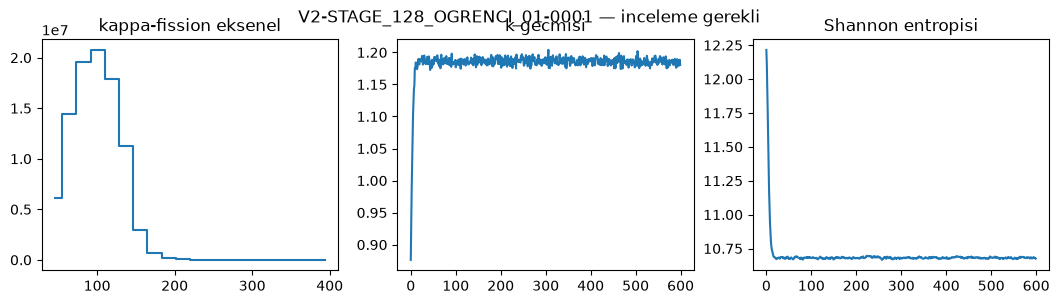

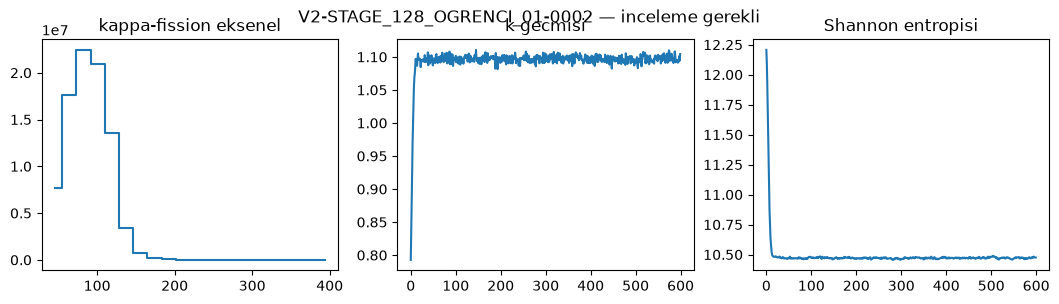

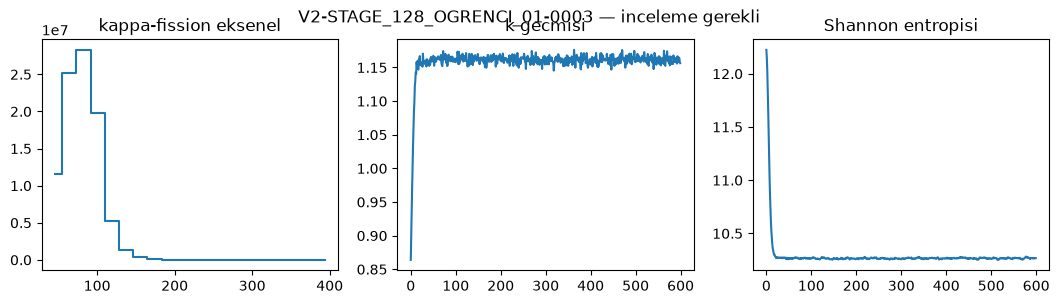

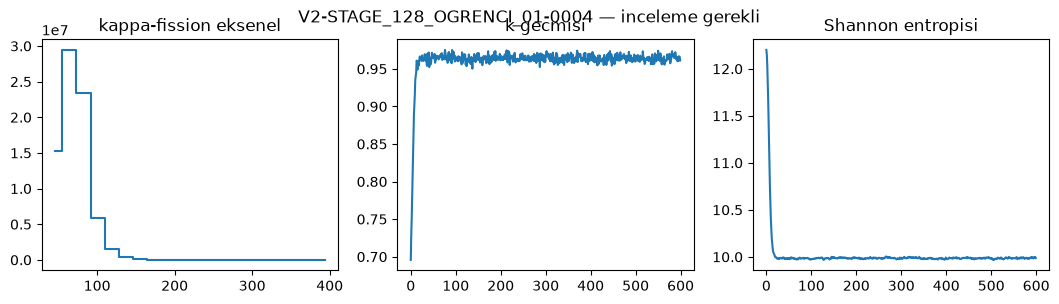

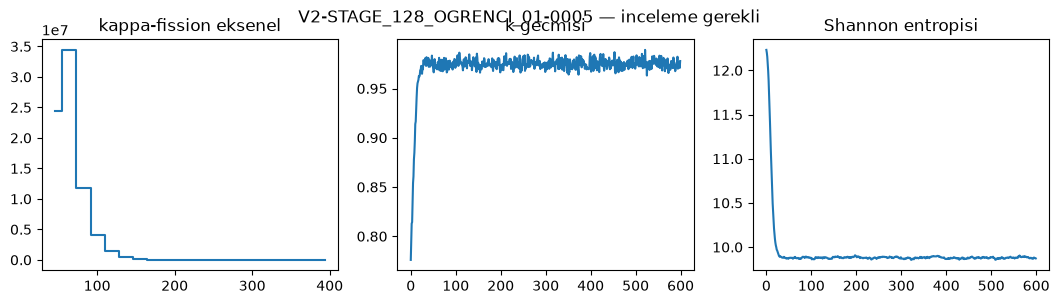

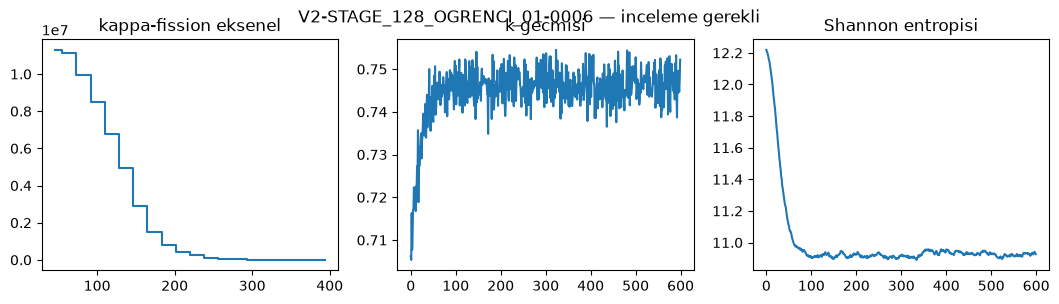

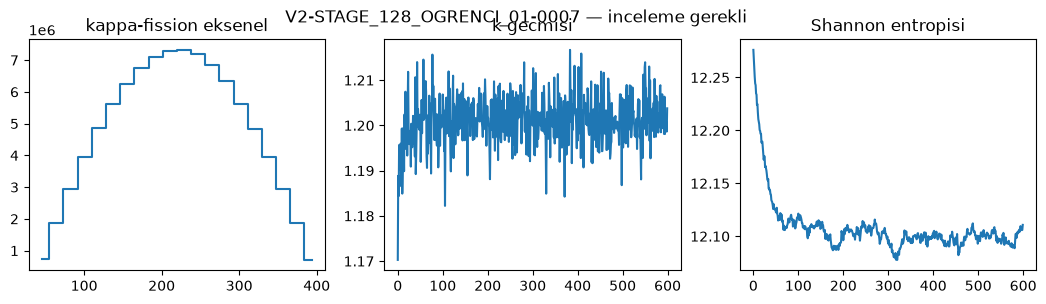

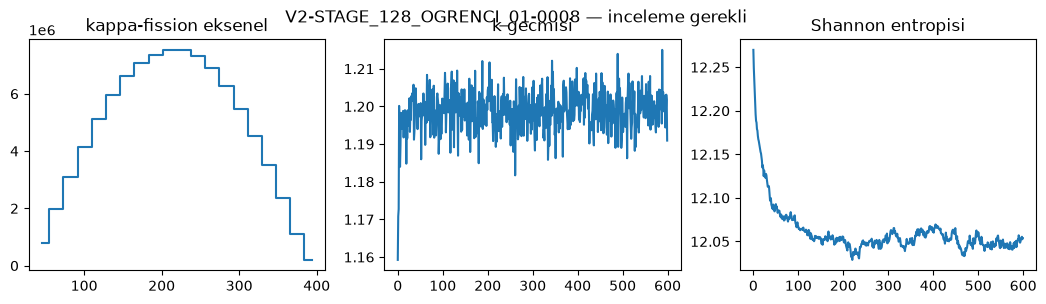

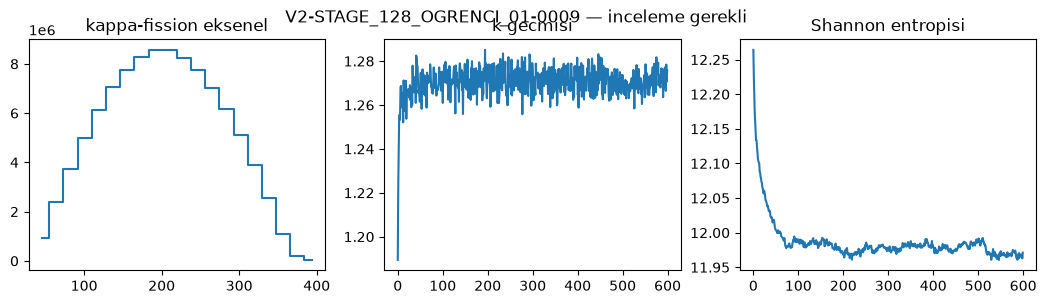

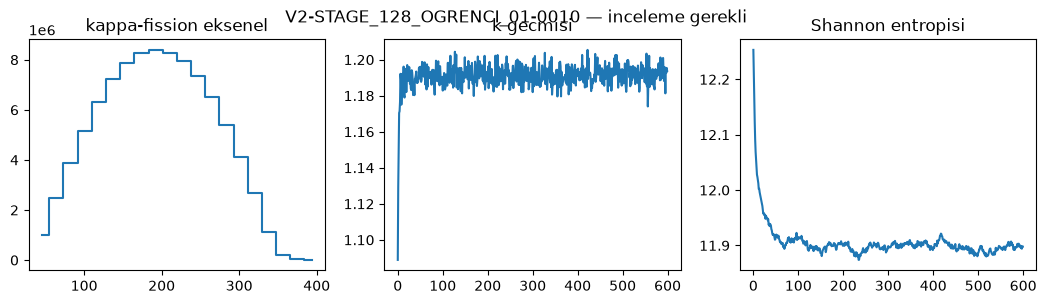

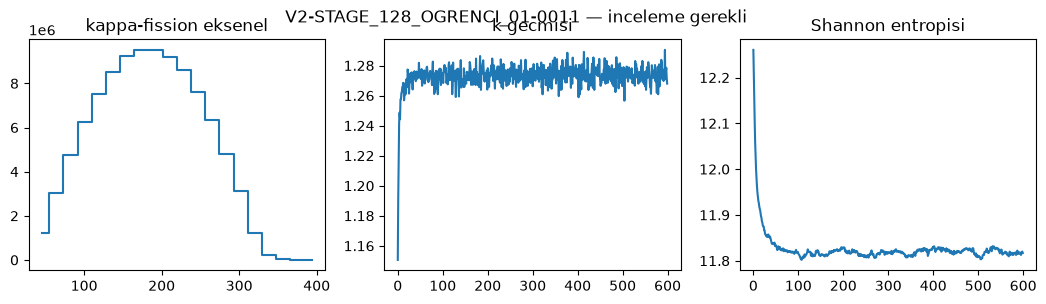

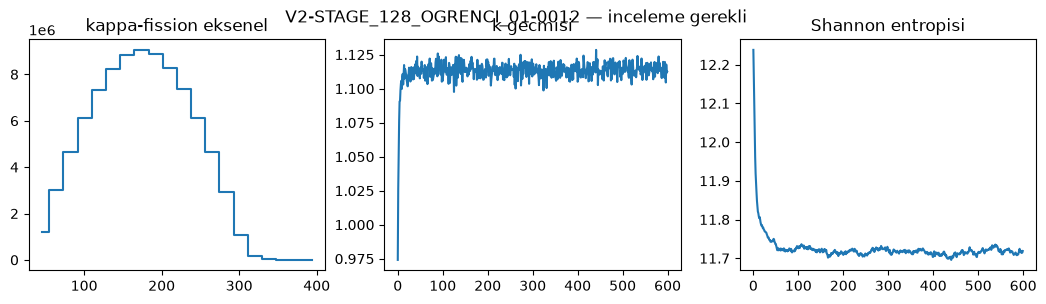

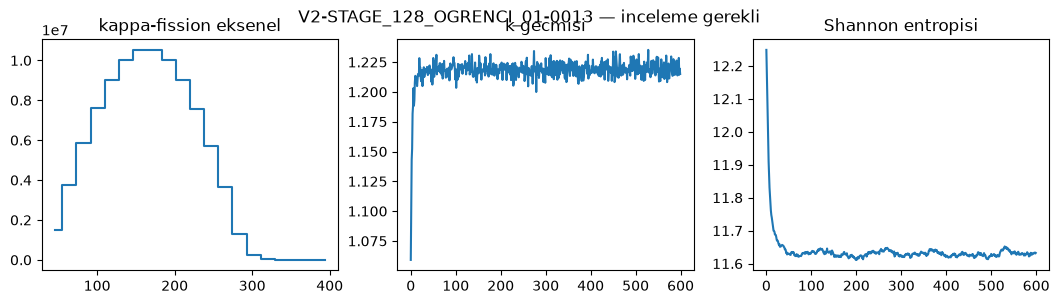

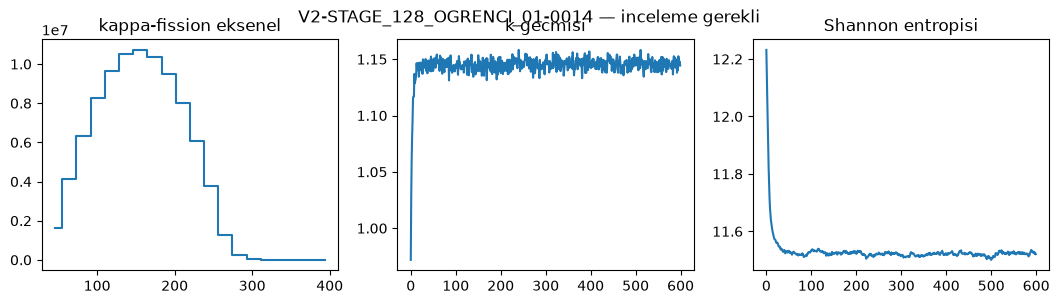

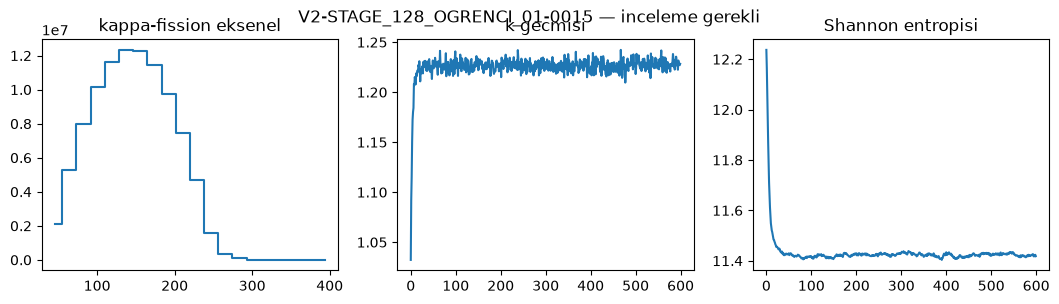

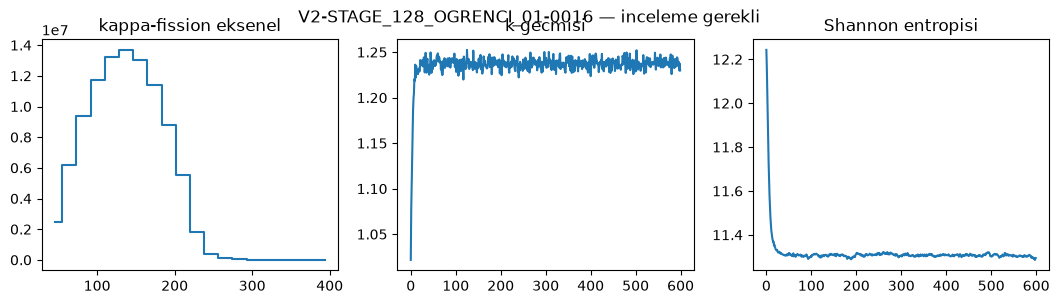

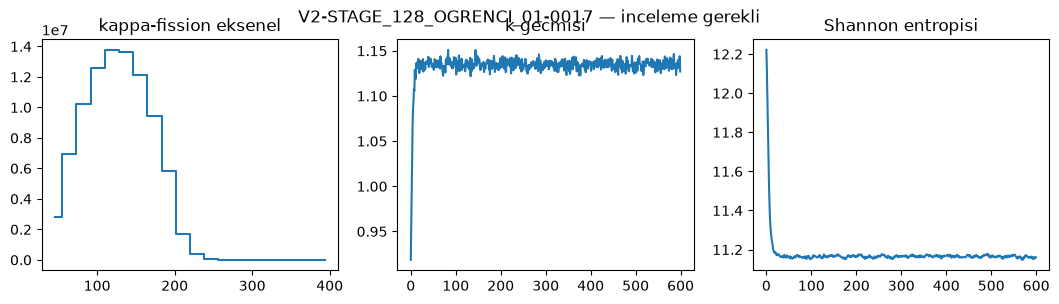

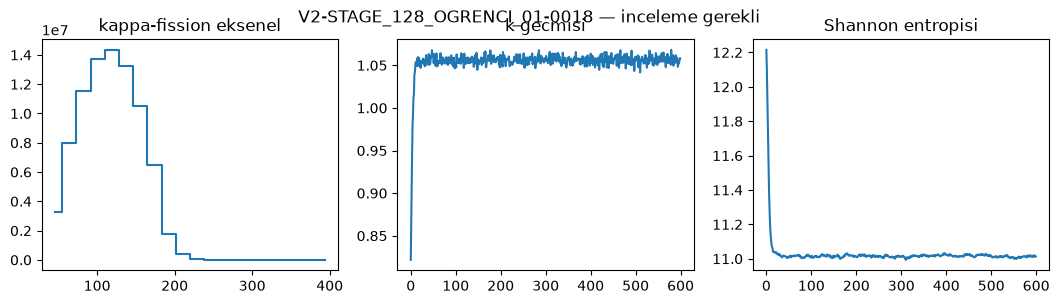

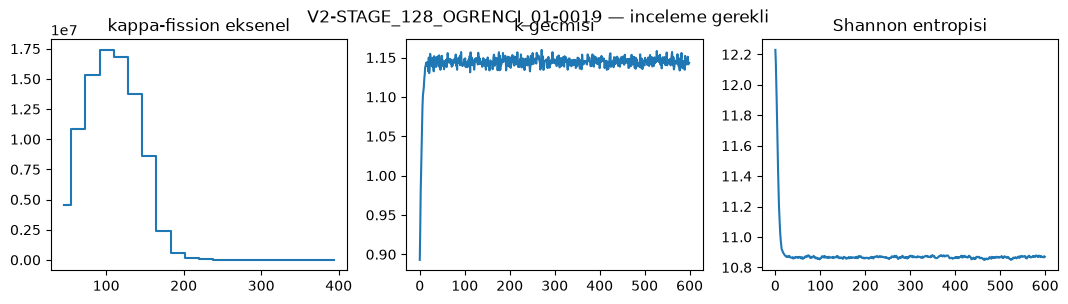

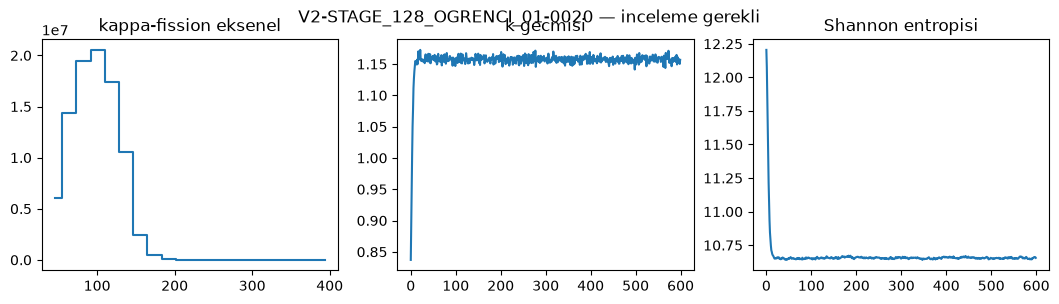

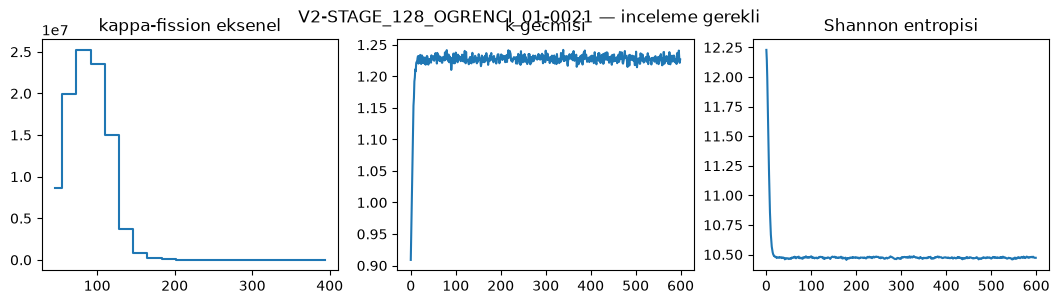

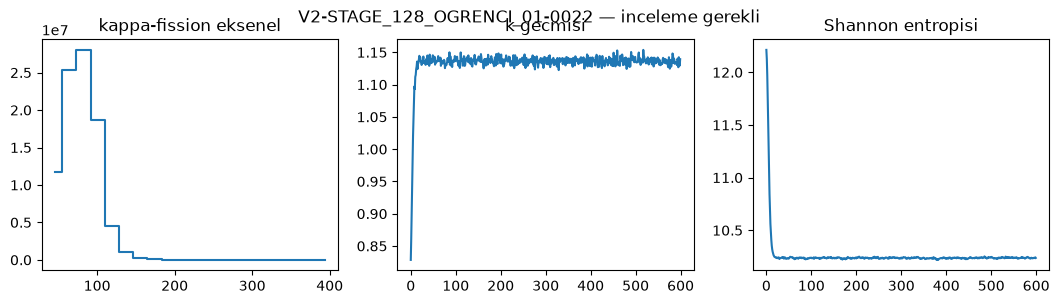

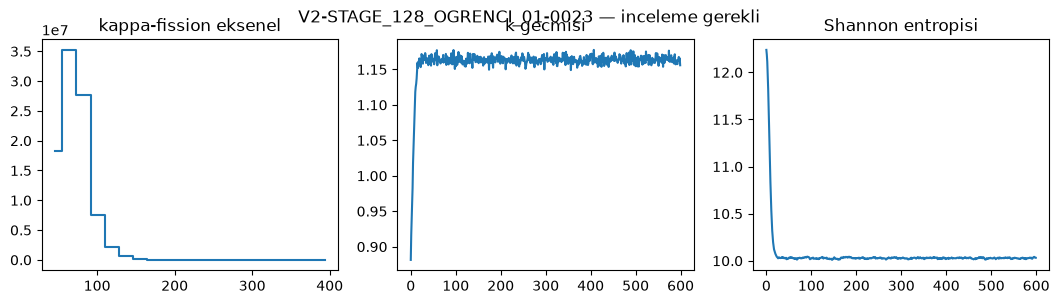

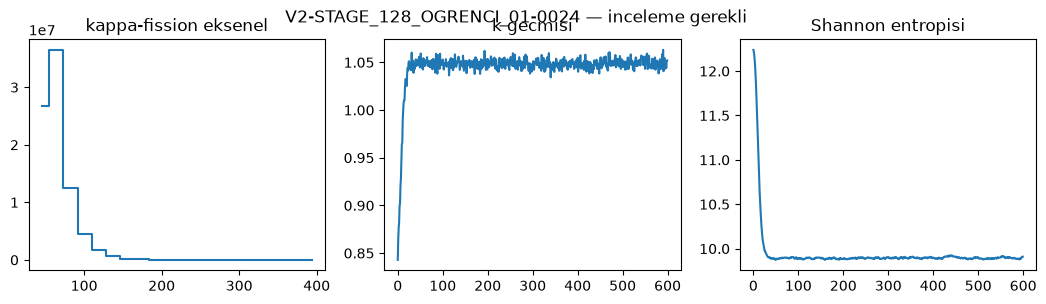

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import json, sys
PACKAGE = Path.cwd().resolve()
PROJECT = next(p for p in (PACKAGE, *PACKAGE.parents) if (p / "src/reactor_pipeline/v2_students.py").is_file())
sys.path.insert(0, str(PROJECT / "src"))
from reactor_pipeline import v2_student_runner, v2_students
assert PACKAGE.name == "v2_stage_128_ogrenci_01_beavrs_v2_pilot_scope_v1"
info = v2_students.verify_package(PACKAGE, require_approval=False)
saved = v2_student_runner.saved_results(PACKAGE)
print("Grup:", saved["group"]["state"], "| completed fiziksel kabul degildir")
rows = []
for case in saved["cases"]:
    summary = case["summary"] or {}
    k = summary.get("k_effective", {})
    manifest_case = next(x for x in v2_students._read(PACKAGE / "manifest.json")["experiments"]
                         if x["experiment_id"] == case["experiment_id"])
    rows.append({"experiment_id": case["experiment_id"],
                 "scenario_id": case["scenario_id"], "state": case["state"],
                 "controls": manifest_case["controls"], "calculation": manifest_case["calculation"],
                 "k": k.get("mean"), "MC_standard_error": k.get("mc_standard_error"),
                 "duration_s": summary.get("duration", {}).get("value"),
                 "fields_npz": str(Path(case["attempt"]) / "fields.npz") if case["attempt"] else None,
                 "summary_json": str(Path(case["attempt"]) / "summary.json") if case["attempt"] else None,
                 "physical_acceptance": case["physical_acceptance"],
                 "statistical_convergence": case["statistical_convergence"]})
display(pd.DataFrame(rows))
for case in saved["cases"]:
    if case["state"] != "completed":
        continue
    with np.load(Path(case["attempt"]) / "fields.npz", allow_pickle=False) as fields:
        z = fields["z_edges_cm"]
        axial = fields["kappa_fission_mean"].sum(axis=(1, 2))
        k_history = fields["k_generation"].copy()
        entropy = fields["shannon_entropy"].copy()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    axes[0].step((z[:-1]+z[1:])/2, axial, where="mid")
    axes[0].set_title("kappa-fission eksenel")
    axes[1].plot(k_history); axes[1].set_title("k gecmisi")
    axes[2].plot(entropy); axes[2].set_title("Shannon entropisi")
    fig.suptitle(case["experiment_id"] + " — inceleme gerekli")
    display(fig)
    plt.close(fig)


## Teslim — hesap başlatmaz
Tamamlanan koşular için WSL terminalinde: `python scripts/v2_transfer.py export student_packages/v2_students_portable_v1/stage_128/ogrenci_01/v2_stage_128_ogrenci_01_beavrs_v2_pilot_scope_v1 deliveries/v2_stage_128_ogrenci_01_beavrs_v2_pilot_scope_v1.zip`. Durum `completed` olmadan teslim tam sayılmaz; varsayılan ZIP statepoint içermez.
